<a href="https://colab.research.google.com/github/jeevithajeevitha3420-create/Data-Science/blob/main/Task_1_DS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("retail_sales_dataset.csv", parse_dates=["Order Date"])
print(df.shape)
df.head()

(4040, 9)


,Order Date,Category,Sub-Category,Customer ID,Region,Sales,Quantity,Discount,Profit
0,2024-10-14,Technology,Laptops,C0439,Central,4969.58,7,0.2,-208.65
1,2024-09-26,Technology,Laptops,C0570,West,3328.23,3,0.1,60.53
2,2025-03-26,Office Supplies,Binders,C0379,Central,91.17,5,0.0,32.73
3,2025-04-22,Furniture,Tables,C0103,West,843.24,2,0.0,-107.64
4,2024-04-22,Furniture,Bookcases,C0335,West,1613.42,6,0.1,-56.44


In [ ]:
df.info()
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print(df["Category"].unique())
print(df["Region"].unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4040 entries, 0 to 4039
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order Date    4040 non-null   datetime64[ns]
 1   Category      4040 non-null   object        
 2   Sub-Category  4040 non-null   object        
 3   Customer ID   4040 non-null   object        
 4   Region        4000 non-null   object        
 5   Sales         3979 non-null   float64       
 6   Quantity      4040 non-null   int64         
 7   Discount      4040 non-null   float64       
 8   Profit        4040 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 284.2+ KB
Order Date       0
Category         0
Sub-Category     0
Customer ID      0
Region          40
Sales           61
Quantity         0
Discount         0
Profit           0
dtype: int64
Duplicates: 40
['Technology' 'Office Supplies' 'Furniture' 'OFFICE SUPPLIES' 

In [ ]:
df = df.drop_duplicates()

df["Category"] = df["Category"].str.strip().str.title()
df["Region"] = df["Region"].str.strip().str.title()

df["Region"] = df["Region"].fillna(df["Region"].mode()[0])
df["Sales"] = df.groupby("Sub-Category")["Sales"].transform(lambda s: s.fillna(s.median()))

df["Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Margin"] = df["Profit"] / df["Sales"]

print(df.isna().sum().sum(), len(df))   # expect 0 and 4000

0 4000


In [ ]:
print(df[["Sales", "Profit", "Quantity"]].describe().round(2))
print("Total sales :", round(df["Sales"].sum()))
print("Total profit:", round(df["Profit"].sum()))
print("Margin %    :", round(df["Profit"].sum() / df["Sales"].sum() * 100, 1))

cat = df.groupby("Category")[["Sales", "Profit", "Quantity"]].sum()
sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
reg = df.groupby("Region")[["Sales", "Profit"]].sum()
print(cat); print(sub); print(reg)

cust = df.groupby("Customer ID").agg(Sales=("Sales", "sum"), Orders=("Sales", "size")).sort_values("Sales", ascending=False)
print(cust.head(10))
top = int(len(cust) * 0.1)
print("Top 10% share:", round(cust["Sales"].head(top).sum() / cust["Sales"].sum() * 100, 1), "%")

          Sales   Profit  Quantity
count   4000.00  4000.00   4000.00
mean    1081.58    10.24      4.01
std     1411.88   173.52      2.01
min        7.76  -867.64      1.00
25%      111.98   -15.26      2.00
50%      465.82    18.84      4.00
75%     1617.28    53.63      6.00
max    10705.09   854.18      7.00
Total sales : 4326301
Total profit: 40972
Margin %    : 0.9
                       Sales     Profit  Quantity
Category                                         
Furniture        1668297.010 -117492.10      5353
Office Supplies   136375.875   28776.86      5308
Technology       2521628.070  129687.05      5373
                    Sales     Profit
Sub-Category                        
Laptops       1646233.810   37025.88
Phones         771602.570   72821.58
Tables         673040.670 -115185.53
Bookcases      579700.530  -20896.55
Chairs         415555.810   18589.98
Accessories    103791.690   19839.59
Storage         72763.105    9385.21
Paper           37563.900   13299.31
Binde

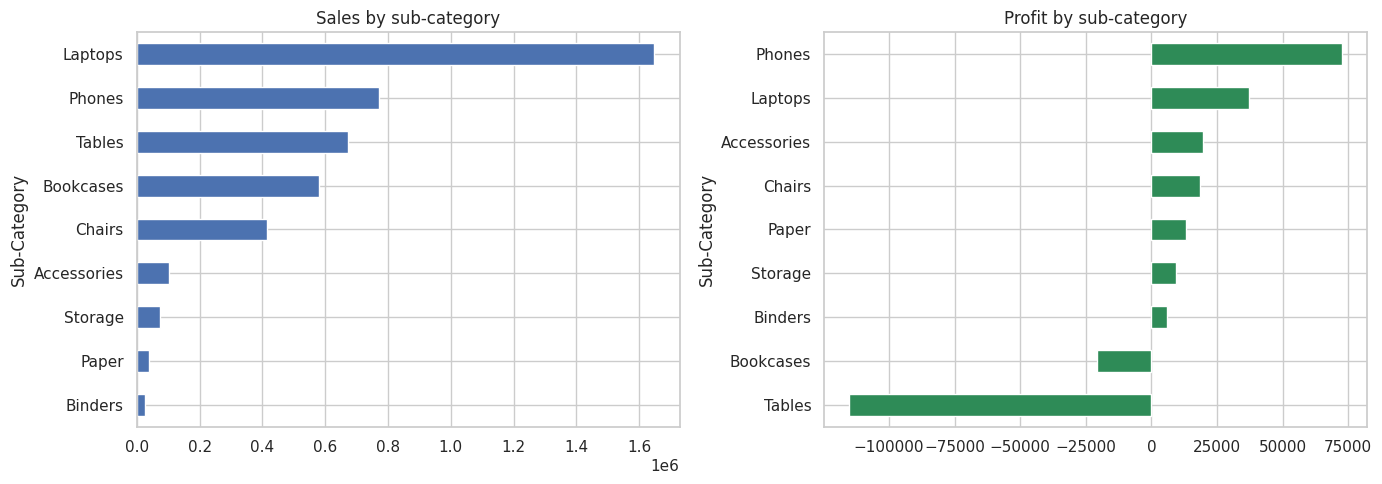

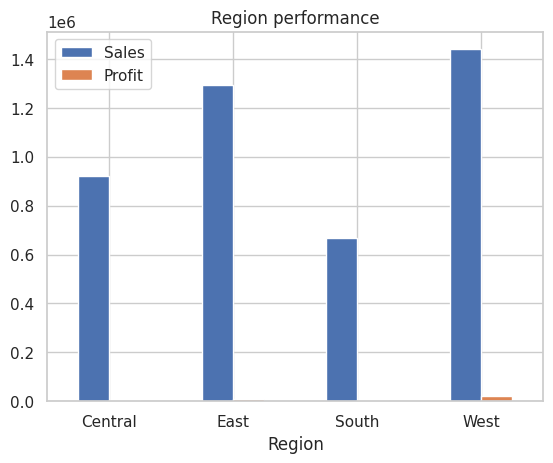

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sub["Sales"].sort_values().plot.barh(ax=ax[0], title="Sales by sub-category")
sub["Profit"].sort_values().plot.barh(ax=ax[1], title="Profit by sub-category", color="seagreen")
plt.tight_layout(); plt.show()

reg[["Sales", "Profit"]].plot.bar(title="Region performance", rot=0); plt.show()

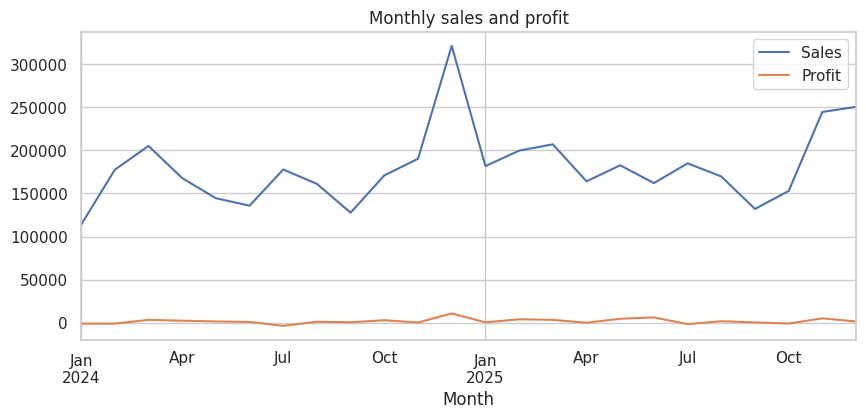

In [ ]:
monthly = df.groupby("Month")[["Sales", "Profit"]].sum()
monthly.plot(figsize=(10, 4), title="Monthly sales and profit")
plt.show()

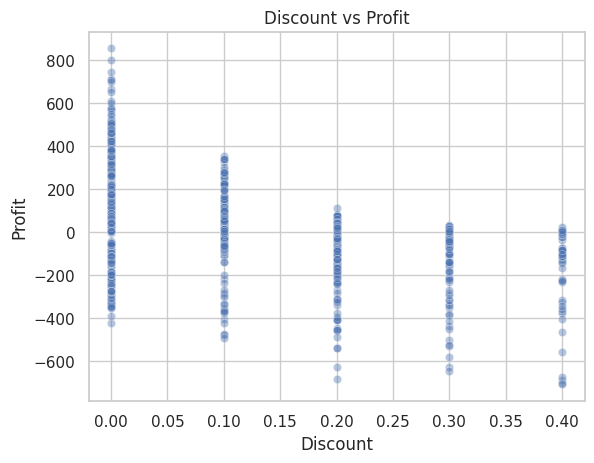

Discount
0.0     76.1
0.1     10.9
0.2    -55.3
0.3    -94.9
0.4   -134.7
Name: Profit, dtype: float64


In [ ]:
sns.scatterplot(x="Discount", y="Profit", data=df.sample(1500, random_state=1), alpha=0.4)
plt.title("Discount vs Profit"); plt.show()
print(df.groupby("Discount")["Profit"].mean().round(1))

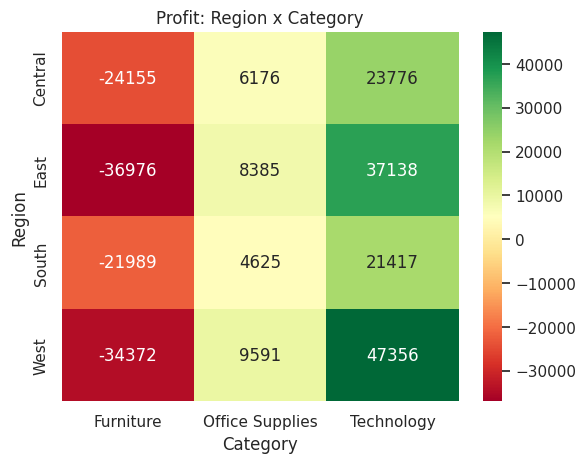

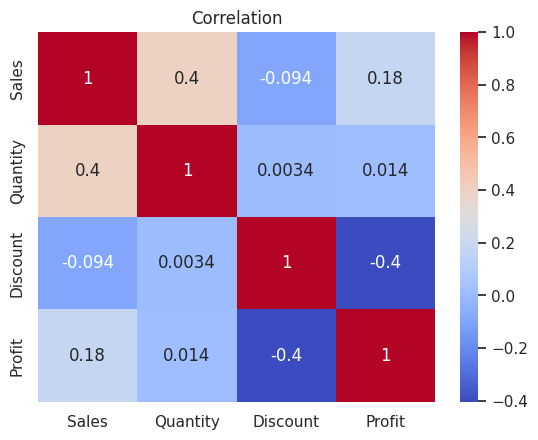

In [ ]:
pivot = df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum")
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn")
plt.title("Profit: Region x Category"); plt.show()

sns.heatmap(df[["Sales", "Quantity", "Discount", "Profit"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation"); plt.show()